
# Difference-in-Differences (DiD) Analysis

## Objective
Estimate the change in North region revenue after the simulated pricing intervention, relative to the revenue changes in the South and West control regions.

## Intervention Details
- Treated region: North
- Control regions: South and West
- Intervention date: 2025-05-01
- Pre-intervention period: 2025-01-01 to 2025-04-30
- Post-intervention period: 2025-05-01 to 2025-06-29

## Method
DiD = (North Post - North Pre) - (Average Control Post - Average Control Pre)


In [1]:

import pandas as pd
import numpy as np

df = pd.read_csv("project1_algorithmic_pricing_synthetic_dataset.csv")

df["date"] = pd.to_datetime(df["date"])

print("Dataset shape:", df.shape)
print("Regions:", df["region"].unique())
print("Date range:", df["date"].min(), "to", df["date"].max())

display(df.head())


Dataset shape: (540, 11)
Regions: <StringArray>
['North', 'South', 'West']
Length: 3, dtype: str
Date range: 2025-01-01 00:00:00 to 2025-06-29 00:00:00


,date,region,product_category,our_price,competitor_price,units_sold,revenue,marketing_spend,promotion_active,treatment,period
0,2025-01-01,North,Home Essentials,501.50,494.80,101,50651.59,474.38,0,0,pre_treatment
1,2025-01-01,South,Home Essentials,489.38,490.19,100,48937.65,417.33,0,0,pre_treatment
2,2025-01-01,West,Home Essentials,509.40,511.37,118,60109.02,449.37,0,0,pre_treatment
3,2025-01-02,North,Home Essentials,499.37,502.85,109,54431.06,345.83,0,0,pre_treatment
4,2025-01-02,South,Home Essentials,486.93,494.56,107,52101.37,381.01,0,0,pre_treatment


In [2]:

# Separate pre-intervention and post-intervention periods

df["period"] = df["period"].astype(str)

revenue_summary = (
    df.groupby(["region", "period"])["revenue"]
      .mean()
      .unstack()
      .round(2)
)

display(revenue_summary)


period,post_treatment,pre_treatment
region,,
North,66366.44,61944.39
South,57908.53,56217.24
West,69749.19,66476.99


In [3]:

# Calculate pre-post revenue changes

revenue_change = (
    revenue_summary["post_treatment"]
    - revenue_summary["pre_treatment"]
)

# Separate treated and control regions
north_change = revenue_change["North"]
south_change = revenue_change["South"]
west_change = revenue_change["West"]

# Average control-region change
average_control_change = (south_change + west_change) / 2

# Difference-in-Differences estimate
did_estimate = north_change - average_control_change

print("North revenue change:", round(north_change, 2))
print("South revenue change:", round(south_change, 2))
print("West revenue change:", round(west_change, 2))
print("Average control change:", round(average_control_change, 2))
print("DiD estimate:", round(did_estimate, 2))


North revenue change: 4422.05
South revenue change: 1691.29
West revenue change: 3272.2
Average control change: 2481.74
DiD estimate: 1940.31


In [4]:

# Create a DiD results summary table

did_summary = pd.DataFrame({
    "Region": ["North", "South", "West", "Average Control"],
    "Pre_Revenue": [
        revenue_summary.loc["North", "pre_treatment"],
        revenue_summary.loc["South", "pre_treatment"],
        revenue_summary.loc["West", "pre_treatment"],
        (revenue_summary.loc["South", "pre_treatment"] +
         revenue_summary.loc["West", "pre_treatment"]) / 2
    ],
    "Post_Revenue": [
        revenue_summary.loc["North", "post_treatment"],
        revenue_summary.loc["South", "post_treatment"],
        revenue_summary.loc["West", "post_treatment"],
        (revenue_summary.loc["South", "post_treatment"] +
         revenue_summary.loc["West", "post_treatment"]) / 2
    ],
    "Revenue_Change": [
        north_change, south_change, west_change, average_control_change
    ]
})

display(did_summary.round(2))

print(f"DiD Estimate: {did_estimate:.2f}")


,Region,Pre_Revenue,Post_Revenue,Revenue_Change
0,North,61944.39,66366.44,4422.05
1,South,56217.24,57908.53,1691.29
2,West,66476.99,69749.19,3272.20
3,Average Control,61347.12,63828.86,2481.74


DiD Estimate: 1940.31


In [5]:

did_summary = did_summary.set_index("Region")

display(did_summary.round(2))


,Pre_Revenue,Post_Revenue,Revenue_Change
Region,,,
North,61944.39,66366.44,4422.05
South,56217.24,57908.53,1691.29
West,66476.99,69749.19,3272.20
Average Control,61347.12,63828.86,2481.74


In [6]:

did_summary.index.name = "Region"
did_summary.columns = [
    "Pre_Revenue",
    "Post_Revenue",
    "Revenue_Change"
]

display(did_summary.round(2))


,Pre_Revenue,Post_Revenue,Revenue_Change
Region,,,
North,61944.39,66366.44,4422.05
South,56217.24,57908.53,1691.29
West,66476.99,69749.19,3272.20
Average Control,61347.12,63828.86,2481.74


In [7]:

# Preliminary method comparison

comparison = pd.DataFrame({
    "Method": [
        "Difference-in-Differences (DiD)",
        "Synthetic Control"
    ],
    "Result": [
        did_estimate,
        np.nan
    ],
    "Metric": [
        "Estimated revenue difference",
        "Pre-treatment MSE"
    ],
    "Metric_Value": [
        did_estimate,
        36627510.23
    ],
    "Interpretation": [
        "North's pre-post revenue change minus average control change",
        "Measures pre-treatment fit; not a treatment effect"
    ]
})

display(comparison.round(2))


,Method,Result,Metric,Metric_Value,Interpretation
0,Difference-in-Differences (DiD),1940.31,Estimated revenue difference,1940.31,North's pre-post revenue change minus average ...
1,Synthetic Control,NaN,Pre-treatment MSE,36627510.23,Measures pre-treatment fit; not a treatment ef...


In [8]:

comparison = comparison.reset_index(drop=True)
display(comparison.round(2))


,Method,Result,Metric,Metric_Value,Interpretation
0,Difference-in-Differences (DiD),1940.31,Estimated revenue difference,1940.31,North's pre-post revenue change minus average ...
1,Synthetic Control,NaN,Pre-treatment MSE,36627510.23,Measures pre-treatment fit; not a treatment ef...


In [9]:

# Aggregate revenue by date and region
daily_region_revenue = (
    df.groupby(["date", "region"])["revenue"]
      .sum()
      .unstack()
      .sort_index()
)

# Construct synthetic North using donor weights
daily_region_revenue["synthetic_north"] = (
    0.5 * daily_region_revenue["South"]
    + 0.5 * daily_region_revenue["West"]
)

# Calculate actual minus synthetic revenue
daily_region_revenue["gap"] = (
    daily_region_revenue["North"]
    - daily_region_revenue["synthetic_north"]
)

# Separate pre- and post-intervention periods
intervention_date = pd.Timestamp("2025-05-01")

pre_gap = daily_region_revenue.loc[
    daily_region_revenue.index < intervention_date, "gap"
]

post_gap = daily_region_revenue.loc[
    daily_region_revenue.index >= intervention_date, "gap"
]

# Estimate average change in the gap
synthetic_control_effect = post_gap.mean() - pre_gap.mean()

print("Average pre-intervention gap:", round(pre_gap.mean(), 2))
print("Average post-intervention gap:", round(post_gap.mean(), 2))
print("Synthetic Control estimated effect:", round(synthetic_control_effect, 2))


Average pre-intervention gap: 597.27
Average post-intervention gap: 2537.58
Synthetic Control estimated effect: 1940.31


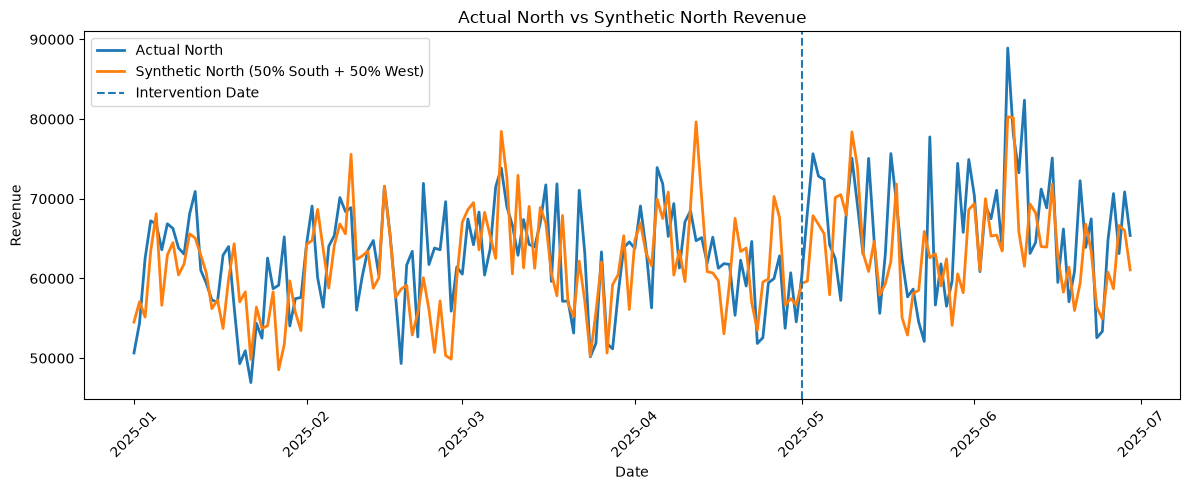

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    daily_region_revenue.index,
    daily_region_revenue["North"],
    label="Actual North",
    linewidth=2
)

plt.plot(
    daily_region_revenue.index,
    daily_region_revenue["synthetic_north"],
    label="Synthetic North (50% South + 50% West)",
    linewidth=2
)

plt.axvline(
    pd.Timestamp("2025-05-01"),
    linestyle="--",
    label="Intervention Date"
)

plt.title("Actual North vs Synthetic North Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## Final Results Summary

### Difference-in-Differences (DiD)
The North region's average revenue increased by 4,422.05 from the pre-intervention period to the post-intervention period. The average change across the South and West control regions was 2,481.74.

The preliminary DiD estimate was **1,940.31**.

### Synthetic Control
Using equal weights of 0.50 for South and 0.50 for West, the average North-minus-synthetic revenue gap was 597.27 before the intervention and 2,537.58 after the intervention.

The preliminary change in the gap was **1,940.31**.

### Interpretation
Both calculations produce the same estimate because they use the same equal-weight control-region combination. This is not independent confirmation from two separately fitted causal methods.

### Limitations
- The dataset is synthetic teaching data, not real company data.
- Equal donor weights were used for this preliminary comparison.
- Pre-intervention fit and regional trends must be assessed before making a causal claim.
- The estimate is not definitive evidence that the pricing intervention caused the revenue increase.
